# Garantías, período de riesgo de margen y margen inicial

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el notebook 01 de este tema (la exposición de un swap)
- **Tiempo de lectura:** unos 50 minutos

**Pregunta:** ¿Cuánta de la exposición del conjunto de neteo elimina un acuerdo de márgenes, cuánta vuelve cuando el período de riesgo de margen se duplica de 10 a 20 días, y qué queda una vez que se entrega margen inicial además?

## Objetivos

Al terminar este notebook puedes:

- calcular el monto de apoyo crediticio y el monto de entrega de un acuerdo de márgenes con umbral y monto mínimo de transferencia, y leer cada caso de la regla;
- enunciar los pisos supervisores del período de riesgo de margen (MPoR) y cómo la frecuencia de reposición de márgenes lo alarga;
- explicar la grilla de cierre y el valor de cierre de fecha pegajosa, y por qué una exposición con garantía sigue siendo positiva;
- calcular la exposición del conjunto de neteo bajo un CSA con MPoR de 10 y de 20 días y compararla con la exposición sin garantía;
- calcular el margen inicial dinámico (DIM) por regresión, aplicarlo, y decir por qué los pesos de ISDA SIMM no se reimplementan.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.ccr import collateral as col
from riskvalidation.ccr import exposure as ex
from riskvalidation.ccr import hw1f
from riskvalidation.ccr import swaps as sw

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Los datos son tres variantes del caso C12 (riesgo de crédito de contraparte), sobre los mismos cuatro swaps sintéticos y la misma curva del Tesoro de EE. UU. del 2025-09-30 del notebook 01. Las operaciones son convenciones del caso, las entradas de mercado son reales y cada número de abajo se reconstruye desde la curva, la calibración, la semilla y el número de trayectorias versionados.

- **Archivos que se leen:** `data/derived/C12/netting-set.json` (curva, calibración y los cuatro swaps, sin garantía), `csa-mpor-10d.json` y `csa-mpor-20d.json` (un CSA con umbral cero, monto mínimo de transferencia de 10.000 USD y reposición diaria, con MPoR de 10 y 20 días hábiles) y `with-im.json` (el CSA de 10 días más margen inicial).
- **Qué agrega cada variante:** el bloque `collateral` tiene el acuerdo y el saldo medio de garantía; el bloque `initial_margin` tiene el DIM.
- **Límites que declara el documento:** no se modelan las cronologías de Andersen, Pykhtin y Sokol (2017), y el DIM es una aproximación por regresión, nunca SIMM.

La celda siguiente carga los cuatro documentos e imprime el acuerdo y el método de margen inicial.

In [2]:
# Cargar los cuatro documentos versionados de C12 (el notebook está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C12"
names = ("netting-set", "csa-mpor-10d", "csa-mpor-20d", "with-im")
docs = {n: json.loads((derived / f"{n}.json").read_text(encoding="utf-8")) for n in names}
base = docs["netting-set"]["outputs"]
csa = docs["csa-mpor-10d"]["outputs"]["collateral"]["csa"]
csa_20 = docs["csa-mpor-20d"]["outputs"]["collateral"]["csa"]
im = docs["with-im"]["outputs"]["initial_margin"]

for key in ("threshold", "minimum_transfer_amount", "independent_amount"):
    print(f"{key:26s}", csa[key]["amount"], csa[key]["currency"])
print("MPoR (días hábiles), variante de 10 días:", csa["mpor_business_days"],
      "| variante de 20 días:", csa_20["mpor_business_days"])
print("reposición cada", csa["remargining_days"], "día(s)")
print("margen inicial por regresión, SIMM usado:", "sí" if im["simm_used"] else "no")
print("cuantil", im["quantile"], "| horizonte / MPoR en días corridos",
      im["horizon_calendar_days"], "/", im["mpor_calendar_days"])
print("orden de regresión", im["regression_order"])

threshold                  0.0 USD
minimum_transfer_amount    10000.0 USD
independent_amount         0.0 USD
MPoR (días hábiles), variante de 10 días: 10 | variante de 20 días: 20
reposición cada 1 día(s)
margen inicial por regresión, SIMM usado: no
cuantil 0.99 | horizonte / MPoR en días corridos 14 / 14
orden de regresión 2


## Método

### Paso 1: el monto de apoyo crediticio y el monto de entrega

Un acuerdo de márgenes fija cuánta garantía deben mantener las dos partes para un valor dado del conjunto de neteo. Con $x = \mathrm{NPV} + \mathrm{IA}$ (IA el monto independiente), un umbral de recepción $Th_{rec}$ y un umbral de pago $Th_{pay}$, el monto de apoyo crediticio es (metodología de ORE, ecuación CSA):

$$\mathrm{CSA} = \begin{cases} \max(0,\ x - Th_{rec}) & x \ge 0 \\ \min(0,\ x + Th_{pay}) & x < 0 \end{cases}$$

El monto es positivo cuando el banco mantiene garantía. El monto de entrega mueve el saldo $C$ hacia el CSA, pero solo cuando el llamado es suficientemente grande. Con $M$ los llamados ya pendientes y $\mathrm{MTA}$ el monto mínimo de transferencia, $\Delta = \mathrm{CSA} - C - M$ y el monto entregado es $D = \Delta$ si $|\Delta| \ge \mathrm{MTA}$ y 0 en otro caso. La celda siguiente evalúa ambos sobre una escalera de valores, una vez con umbral cero y otra con umbral de 100.000 USD, y luego muestra qué hace el monto mínimo de transferencia con un llamado pequeño.

In [3]:
# El monto de apoyo crediticio para dos umbrales sobre una escalera de valores, y el monto de entrega con un MTA
npv = np.array([-300e3, -150e3, -20e3, 0.0, 5e3, 60e3, 150e3, 400e3])
csa_zero = col.credit_support_amount(npv, 0.0, 0.0, 0.0)
csa_100k = col.credit_support_amount(npv, 0.0, 100e3, 100e3)
print(f"{'NPV':>10s} {'CSA TH=0':>10s} {'CSA TH=100k':>12s}")
for v, c0, c1 in zip(npv, csa_zero, csa_100k):
    print(f"{v:10.0f} {c0:10.0f} {c1:12.0f}")

balance, outstanding, mta = np.zeros_like(npv), np.zeros_like(npv), 10e3
print("entrega con MTA = 10000 y saldo vacío:",
      col.delivery_amount(csa_zero, balance, outstanding, mta))
print("entrega con MTA = 0:", col.delivery_amount(csa_zero, balance, outstanding, 0.0))

       NPV   CSA TH=0  CSA TH=100k
   -300000    -300000      -200000
   -150000    -150000       -50000
    -20000     -20000            0
         0          0            0
      5000       5000            0
     60000      60000            0
    150000     150000        50000
    400000     400000       300000
entrega con MTA = 10000 y saldo vacío: [-300000. -150000.  -20000.       0.       0.   60000.  150000.  400000.]
entrega con MTA = 0: [-300000. -150000.  -20000.       0.    5000.   60000.  150000.  400000.]


La celda siguiente dibuja el monto de apoyo crediticio para cada valor del conjunto de neteo, con umbral cero y con umbral de 100.000 USD.

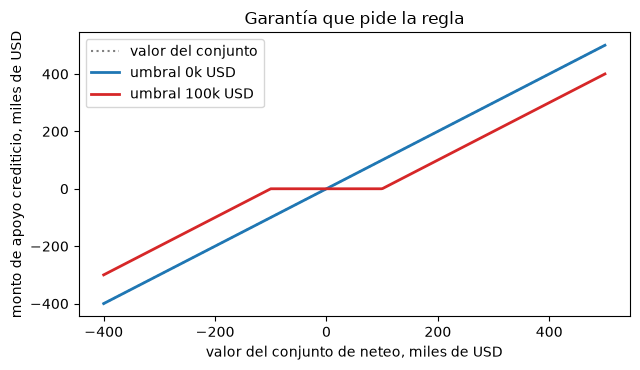

In [4]:
# Dibujar el monto de apoyo crediticio contra el valor del conjunto de neteo para dos umbrales
v = np.linspace(-400e3, 500e3, 400)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(v / 1e3, v / 1e3, color="grey", ls=":", label="valor del conjunto")
for th_value, color in ((0.0, "tab:blue"), (100e3, "tab:red")):
    amount = col.credit_support_amount(v, 0.0, th_value, th_value)
    ax.plot(v / 1e3, amount / 1e3, color=color, lw=2, label=f"umbral {th_value / 1e3:.0f}k USD")
ax.set_xlabel("valor del conjunto de neteo, miles de USD")
ax.set_ylabel("monto de apoyo crediticio, miles de USD")
ax.set_title("Garantía que pide la regla")
ax.legend()
fig.tight_layout()
plt.show()

La línea azul sigue la diagonal punteada: con umbral cero la regla pide toda la garantía que implica el valor, en ambos sentidos. La línea roja tiene un tramo plano de 200.000 USD de ancho alrededor de cero, donde ninguna parte entrega nada, y fuera de él corre paralela a la diagonal, 100.000 USD más abajo. La figura muestra la regla en un instante. No dice cuánto tarda en llegar la garantía, que es el tema del paso siguiente.

### Paso 2: el período de riesgo de margen

Cuando una contraparte deja de pagar, el banco no cierra la posición el mismo día. El MPoR es el tiempo entre la última garantía que el banco recibió y el momento en que la posición se cierra y se recubre. Durante él el valor se mueve y nadie entrega garantía, así que la garantía mantenida se rezaga respecto del valor. Los pisos de Basilea son (CRE53.24 a CRE53.26): 10 días hábiles, 5 para conjuntos de tipo repo, 20 si el conjunto tiene más de 5.000 operaciones o garantía ilíquida, y el doble si hubo más de dos disputas largas en dos trimestres; y con reposición cada $N$ días el período es $F + N - 1$. `mpor_floor` y `mpor_with_remargining`, del motor, devuelven estos números. El caso usa 10 y 20 días hábiles, que convierte a 14 y 28 días corridos porque ORE cuenta el cierre en días corridos.

In [5]:
# Los pisos supervisores del MPoR y el efecto de la reposición, llamando al motor
print("piso por defecto:", col.mpor_floor())
print("conjunto de tipo repo:", col.mpor_floor(repo_only=True))
print("más de 5000 operaciones:", col.mpor_floor(n_trades=5001))
print("garantía ilíquida:", col.mpor_floor(illiquid=True))
print("más de dos disputas, piso por defecto:", col.mpor_floor(disputes_over_two=True))
for days in (1, 5, 10):
    remargin = col.mpor_with_remargining(10, days)
    print(f"reposición cada {days:2d} día(s): MPoR =", remargin, "días hábiles")

deltas = {10: 14 / 360, 20: 28 / 360}
print("desfases de cierre en años en el eje 30/360:",
      {bd: round(d, 6) for bd, d in deltas.items()})

piso por defecto: 10
conjunto de tipo repo: 5
más de 5000 operaciones: 20
garantía ilíquida: 20
más de dos disputas, piso por defecto: 20
reposición cada  1 día(s): MPoR = 10 días hábiles
reposición cada  5 día(s): MPoR = 14 días hábiles
reposición cada 10 día(s): MPoR = 19 días hábiles
desfases de cierre en años en el eje 30/360: {10: 0.038889, 20: 0.077778}


### Paso 3: la simulación y el cierre de fecha pegajosa

Reconstruimos la simulación del notebook 01 (misma curva, calibración, semilla y grilla, con las fechas de cierre en la grilla). La celda siguiente construye los cuatro swaps, simula la tasa corta y valora el conjunto de neteo en las fechas del informe.

In [6]:
# Reconstruir las trayectorias del notebook 01 y los valores del conjunto de neteo en las fechas del informe
tenors = np.array([p["tenor_years"] for p in base["curve"]["points"]])
zeros = np.array([p["zero_rate"] for p in base["curve"]["points"]])
a, sigma = base["calibration_used"]["a"], base["calibration_used"]["sigma"]
p0, forward = hw1f.curve_functions(zeros, tenors)
named = base["named_parameters"]
report = np.array(named["time_grid_years"]["value"])
main = np.concatenate([[0.0], report])
swaps = [
    sw.Swap(t["trade_id"], t["notional"]["amount"], t["fixed_rate"], t["side"] == "payer",
            t["start_years"], t["maturity_years"], t["fixed_frequency_per_year"])
    for t in base["book"]["trades"]
]
merged = np.unique(np.round(np.concatenate([main] + [main + d for d in deltas.values()]), 12))
grid = sw.simulation_grid(merged, swaps)
n_paths, seed = named["path_count"]["value"], named["seed"]["value"]
r = hw1f.simulate_short_rate(grid, a, sigma, forward, n_paths, seed)
numeraire = hw1f.bank_account(grid, r, a, sigma, p0, forward)
values = sw.swap_values_on_grid(swaps, grid, r, a, sigma, p0, forward)
ix_main = np.searchsorted(grid, main - sw.TIME_TOL)
vm = ex.net_values(values[:, :, ix_main])
print("valores del conjunto de neteo (trayectorias, fechas):", vm.shape)

valores del conjunto de neteo (trayectorias, fechas): (20000, 34)


El valor de cierre de un incumplimiento en la fecha $t$ es el valor del conjunto de neteo en $t + \delta$, donde $\delta$ es el MPoR en años. ORE ofrece dos formas de leerlo; el caso usa la de **fecha pegajosa**: el mercado se movió a $t+\delta$, pero la cartera no envejeció, así que un swap en $t+\delta$ conserva los mismos flujos restantes que tenía en $t$. Valorar el swap desplazado hacia adelante en $\delta$ en $t+\delta$ da exactamente eso, y el cupón de un período ya iniciado es el fijado en la trayectoria en su último reinicio. La celda siguiente calcula los valores de cierre pegajosos para ambos MPoR.

In [7]:
# El valor de cierre de fecha pegajosa del conjunto de neteo en cada fecha del informe, para ambos MPoR
ROLL = 1e-7
closeout = {}
for bd, delta in deltas.items():
    cube = np.zeros((len(swaps), r.shape[0], main.size))
    for s_i, swap in enumerate(swaps):
        shifted = sw.Swap(swap.trade_id, swap.notional, swap.fixed_rate, swap.is_payer,
                          swap.start + delta - ROLL, swap.maturity + delta - ROLL, swap.fixed_frequency)
        resets, times = sw.reset_times(swap), sw.cash_flow_times(swap)
        for k, t in enumerate(main):
            if t >= swap.maturity - sw.TIME_TOL:
                continue
            j = int(np.searchsorted(resets, t + sw.TIME_TOL, side="right")) - 1
            i_reset = np.searchsorted(grid, resets[j] - sw.TIME_TOL)
            p_fix = hw1f.bond_price(r[:, i_reset], float(resets[j]), float(times[j]), a, sigma, p0, forward)
            fixing = (1.0 / p_fix - 1.0) / float(times[j] - resets[j])
            i_close = np.searchsorted(grid, t + delta - sw.TIME_TOL)
            cube[s_i, :, k] = sw.swap_value(shifted, float(t + delta), r[:, i_close], a, sigma, p0, forward, fixing)
    closeout[bd] = ex.net_values(cube)

gap = {bd: round(float(np.abs(closeout[bd] - vm).mean()), 0) for bd in closeout}
print("valores de cierre para MPoR de 10 y 20 días:", {bd: v.shape for bd, v in closeout.items()})
print("brecha absoluta media entre valor de cierre y valor, 10 días / 20 días:", gap[10], "/", gap[20])

valores de cierre para MPoR de 10 y 20 días: {10: (20000, 34), 20: (20000, 34)}
brecha absoluta media entre valor de cierre y valor, 10 días / 20 días: 33239.0 / 46978.0


### Paso 4: la exposición bajo margen de variación

Fecha a fecha, `variation_margin_exposure`, del motor, aplica las reglas de apoyo crediticio y entrega sobre los valores de las fechas principales para obtener el saldo $C(t)$, y luego toma la exposición sobre los valores de cierre:

$$E(t) = \max\big(V_{cierre}(t) - C(t),\ 0\big)$$

Esta es la ecuación 4 de Hull y White: la exposición es positiva aun con umbral cero porque la garantía se rezaga respecto del valor en el MPoR, y tiende a cero cuando el MPoR tiende a cero. `collateralised_exposure` es el mismo último paso por separado. Calculamos la EE en la medida $t$-forward como en el notebook 01, para 10 y 20 días, con el monto mínimo de transferencia del caso y sin él.

In [8]:
# EE bajo margen de variación para ambos MPoR, con y sin monto mínimo de transferencia
ix = ix_main[1:]
p0r = p0(report)
nm = numeraire[:, ix]
th, mta_case = csa["threshold"]["amount"], csa["minimum_transfer_amount"]["amount"]
ia = csa["independent_amount"]["amount"]

ee_unc = ex.expected_exposure(vm[:, 1:], nm)[0] / p0r
profile, exposure = {"unc": ee_unc}, {}
eepe = {"unc": ex.effective_epe(report, ex.effective_ee(ee_unc))}
for bd, label in ((10, "10d"), (20, "20d")):
    x, held = col.variation_margin_exposure(vm, closeout[bd], ia, th, th, mta_case)
    exposure[label] = x
    profile[label] = ex.expected_exposure(x[:, 1:], nm)[0] / p0r
    eepe[label] = ex.effective_epe(report, ex.effective_ee(profile[label]))
    x0, _ = col.variation_margin_exposure(vm, closeout[bd], ia, th, th, 0.0)
    ee0 = ex.expected_exposure(x0[:, 1:], nm)[0] / p0r
    eepe[label + "-mta0"] = ex.effective_epe(report, ex.effective_ee(ee0))
    same = col.collateralised_exposure(closeout[bd], held)
    print(f"MPoR {bd} días: mayor diferencia entre collateralised_exposure y la exposición del motor:",
          float(np.max(np.abs(same - x))))

MPoR 10 días: mayor diferencia entre collateralised_exposure y la exposición del motor: 0.0
MPoR 20 días: mayor diferencia entre collateralised_exposure y la exposición del motor: 0.0


La celda siguiente tabula la EEPE y la EE a un año de los tres regímenes, el recorte que hace cada acuerdo frente al conjunto sin garantía, y la EEPE que resultaría sin el monto mínimo de transferencia.

In [9]:
# La EEPE y la EE a un año de los tres regímenes, el recorte que hace cada acuerdo
k1 = np.searchsorted(report, 1.0 - 1e-9)
print(f"{'':16s}{'EEPE':>10s}{'EE a 1 a':>12s}")
for key, label in (("unc", "sin garantía"), ("10d", "CSA, 10 días"), ("20d", "CSA, 20 días")):
    print(f"{label:16s}{eepe[key]:10.0f}{profile[key][k1]:12.0f}")
cut_10, cut_20 = 1 - eepe["10d"] / eepe["unc"], 1 - eepe["20d"] / eepe["unc"]
print("reducción de la EEPE frente al conjunto sin garantía, 10 / 20 días:", f"{cut_10:.0%}", "/", f"{cut_20:.0%}")
print("EEPE del CSA de 20 días frente al de 10 días:", f"{eepe['20d'] / eepe['10d'] - 1:+.0%}")
print("EEPE sin monto mínimo de transferencia, 10 / 20 días:",
      round(eepe["10d-mta0"], 0), "/", round(eepe["20d-mta0"], 0))

                      EEPE    EE a 1 a
sin garantía         59954      101950
CSA, 10 días         22778       20811
CSA, 20 días         33183       30126
reducción de la EEPE frente al conjunto sin garantía, 10 / 20 días: 62% / 45%
EEPE del CSA de 20 días frente al de 10 días: +46%
EEPE sin monto mínimo de transferencia, 10 / 20 días: 22756.0 / 33173.0


La celda siguiente dibuja la exposición esperada del conjunto de neteo sin garantía y bajo los dos acuerdos de márgenes.

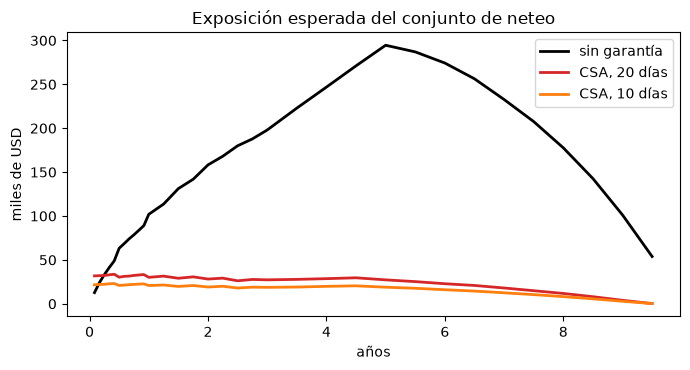

In [10]:
# Dibujar la EE del conjunto de neteo sin garantía y con un CSA de 10 y de 20 días
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(report, ee_unc / 1e3, color="black", lw=2, label="sin garantía")
ax.plot(report, profile["20d"] / 1e3, color="tab:red", lw=2, label="CSA, 20 días")
ax.plot(report, profile["10d"] / 1e3, color="tab:orange", lw=2, label="CSA, 10 días")
ax.set_xlabel("años")
ax.set_ylabel("miles de USD")
ax.set_title("Exposición esperada del conjunto de neteo")
ax.legend()
fig.tight_layout()
plt.show()

La curva negra es la exposición sin ningún acuerdo; las dos curvas de color quedan muy por debajo, y la roja (20 días) queda sobre la naranja (10 días) en todas las fechas. La garantía no lleva la exposición a cero, porque el valor sigue moviéndose durante el período de riesgo de margen, y cuanto más largo es ese período más puede moverse el valor antes de que la garantía lo alcance. La figura compara regímenes sobre una sola simulación: no dice qué período corresponde a una contraparte dada, algo que depende del historial de disputas y de la garantía.

### Paso 5: margen inicial dinámico

El margen inicial se entrega además del margen de variación y cubre el cambio de valor durante el MPoR. ORE lo estima camino por camino con una regresión (metodología de ORE; adendum R2 de la investigación del caso). En cada fecha forma el cambio sobre el MPoR $X = V(t+\mathrm{MPoR}) + F - V(t)$, con $F$ los flujos dentro de la ventana (cero aquí), regresa $X^2$ sobre un polinomio del valor actual para obtener $E[X^2 \mid V(t)]$, y fija

$$S = \sqrt{\max(E[X^2 \mid V(t)] - E[X]^2,\ 0)}, \qquad \mathrm{DIM}(t) = \Phi^{-1}(q)\ S\ \sqrt{h / m}$$

con $q = 99\%$ y $h$ y $m$ el horizonte y el MPoR en días **corridos** (14 y 14). Luego la exposición pasa a ser $\max(E - \mathrm{DIM}, 0)$ camino por camino, aplicada solo sobre el margen de variación. Es una aproximación de un modelo a nivel de operación: los pesos de riesgo de ISDA SIMM se publican bajo un aviso que restringe su uso a las operaciones propias de un participante, así que el motor no los reimplementa y el documento rotula el resultado como una aproximación por regresión, no SIMM. La celda siguiente calcula el DIM en cada fecha, lo aplica y muestra su efecto sobre la exposición.

In [11]:
# El DIM por regresión en cada fecha, aplicado camino por camino a la exposición con margen de variación de 10 días
x_vm = exposure["10d"]
dim = np.column_stack([
    col.dynamic_initial_margin(vm[:, k], closeout[10][:, k], np.zeros(vm.shape[0]), im["quantile"],
                               im["horizon_calendar_days"], im["mpor_calendar_days"], im["regression_order"])
    for k in range(vm.shape[1])
])
x_im = col.apply_initial_margin(x_vm[:, 1:], dim[:, 1:])
ee_vm = profile["10d"]
ee_im = ex.expected_exposure(x_im, nm)[0] / p0r
dim_mean = dim[:, 1:].mean(axis=0)

print("el DIM nunca es negativo y la exposición nunca sube:",
      "sí" if dim.min() >= 0 else "no", "sí" if np.all(x_im <= x_vm[:, 1:] + 1e-9) else "no")
print("DIM medio a 1 a:", round(float(dim_mean[k1]), 0))
print("EE antes / después del IM a 1 a:", round(float(ee_vm[k1]), 0), "/", round(float(ee_im[k1]), 0))
print("EEPE antes / después del IM:", round(ex.effective_epe(report, ex.effective_ee(ee_vm)), 0), "/",
      round(ex.effective_epe(report, ex.effective_ee(ee_im)), 0))
print("alpha = Phi^-1(q):", round(im["alpha"], 6))

el DIM nunca es negativo y la exposición nunca sube: sí sí
DIM medio a 1 a: 110493.0
EE antes / después del IM a 1 a: 20811.0 / 178.0
EEPE antes / después del IM: 22778.0 / 213.0
alpha = Phi^-1(q): 2.326348


La celda siguiente dibuja el margen inicial dinámico medio y la exposición esperada del CSA de 10 días antes y después de aplicarlo.

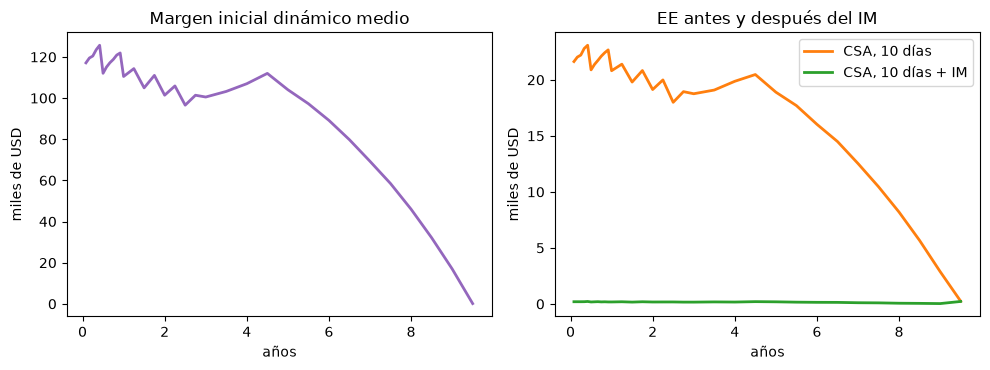

In [12]:
# Dibujar el DIM medio (izquierda) y la EE del CSA de 10 días antes y después del margen inicial (derecha)
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
left.plot(report, dim_mean / 1e3, color="tab:purple", lw=2)
left.set_xlabel("años")
left.set_ylabel("miles de USD")
left.set_title("Margen inicial dinámico medio")
right.plot(report, ee_vm / 1e3, color="tab:orange", lw=2, label="CSA, 10 días")
right.plot(report, ee_im / 1e3, color="tab:green", lw=2, label="CSA, 10 días + IM")
right.set_xlabel("años")
right.set_ylabel("miles de USD")
right.set_title("EE antes y después del IM")
right.legend()
fig.tight_layout()
plt.show()

A la izquierda, el margen medio es mucho mayor que la exposición esperada que protege: está dimensionado para el cuantil de 99% del cambio de valor en el período de riesgo de margen, no para el promedio. A la derecha, la curva verde queda casi plana en cero, así que el margen inicial elimina casi toda la exposición restante. Léelo como la respuesta de una aproximación por regresión y no como un número de capital: los notebooks 07 y 08 muestran que el margen inicial dinámico del propio ORE difiere de este, y el documento versionado informa esa brecha como un hallazgo.

## Resultados

**Respuesta:** Un CSA con período de riesgo de margen de 10 días recorta la EEPE del conjunto de neteo de cuatro swaps de 59.954 USD a 22.778 USD, una reducción de 62%. Duplicar el período a 20 días devuelve una parte, 33.183 USD (45% bajo el conjunto sin garantía), y el margen inicial por regresión sobre el CSA de 10 días, con una media de 110.493 USD a un año, deja una EEPE de 213 USD.

- **La regla.** Con umbral cero el monto de apoyo crediticio es igual al valor (el banco mantiene todo lo que se le debe y entrega todo lo que debe). Un umbral de 100.000 USD deja los primeros 100.000 sin garantía: un valor de 60.000 no necesita garantía y 400.000 necesita 300.000. El monto mínimo de transferencia es una zona muerta: un llamado de 5.000 USD no se entrega cuando el MTA es 10.000, y se entrega cuando el MTA es cero.
- **El período.** El piso es de 10 días hábiles por defecto, 5 para conjuntos de tipo repo, y 20 para conjuntos de más de 5.000 operaciones, con garantía ilíquida, o el doble tras disputas largas. La reposición cada 5 días lo alarga a 14 días hábiles, y cada 10 días a 19: el período es $F + N - 1$. Los 10 y 20 días del caso pasan a ser desfases de cierre de 0,0389 y 0,0778 años en el eje 30/360, y la brecha absoluta media entre el valor de cierre y el valor en la fecha de incumplimiento es 33.239 USD para 10 días y 46.978 USD para 20.
- **La exposición.** La garantía recorta la exposición y no la elimina: el valor se mueve durante el MPoR, y duplicar el MPoR sube la EEPE en 46%. El monto mínimo de transferencia importa poco aquí: sin él la EEPE sería 22.756 y 33.173 USD.
- **Margen inicial.** Aplicado sobre el CSA de 10 días, el DIM por regresión baja la EE a un año de 20.811 USD a 178 USD y la EEPE de 22.778 USD a 213 USD.

Lo que este notebook no muestra: qué cuesta o ahorra la garantía en CVA (notebook 03), el tratamiento SA-CCR de un conjunto con márgenes (notebook 04) y la conciliación con ORE (notebooks 07 y 08).

## Resumen

- El monto de apoyo crediticio depende del valor, del umbral y del monto independiente; el monto de entrega mueve el saldo solo cuando el llamado alcanza el monto mínimo de transferencia.
- El MPoR tiene pisos supervisores (10, 5 o 20 días hábiles, el doble tras disputas) y crece con el intervalo de reposición como $F + N - 1$.
- Una exposición con garantía es $\max(V_{cierre} - C, 0)$: sigue siendo positiva porque la garantía se rezaga respecto del valor, y crece con el MPoR (aquí +46% de EEPE de 10 a 20 días).
- El DIM por regresión, $\Phi^{-1}(q) S \sqrt{h/m}$, elimina la mayor parte de ese resto en este libro; es una aproximación y ORE no coincide con ella.

**Qué probar después.** Cambia el umbral a 100.000 USD en la llamada a `variation_margin_exposure` y mira cuánto de la exposición de 10 días vuelve; fija el orden de regresión en 0 y mira qué pierde el DIM. Luego sigue con el notebook 03.

## Referencias

- BCBS, Basel Framework, CRE53 Internal model method for counterparty credit risk (in force 2023-01-01, published 2020-06-05). https://www.bis.org/basel_framework/chapter/CRE/53.htm?inforce=20230101&published=20200605
- Open Source Risk Engine, Methodology, value adjustments and margin period of risk (xva.tex at tag 1.8.17.0). https://github.com/OpenSourceRisk/Engine/blob/1.8.17.0/Docs/UserGuide/methods/xva.tex
- Andersen, L., Pykhtin, M. and Sokol, A. (2017), Rethinking the margin period of risk, Journal of Credit Risk 13(1). https://doi.org/10.21314/JCR.2016.218
- Hull, J. and White, A. (2012), CVA and wrong way risk, Financial Analysts Journal 68(5), 58-69. https://doi.org/10.2469/faj.v68.n5.6